# 27 Degrees of Freedom Against a 3D Finite-Element Model: Checking a Hospital's Seismic Isolation

This self-contained notebook reproduces every figure and table in the [blog post](https://nouseng.co/posts/bolu-hospital-isolator-sweep/) and [`technical_notes.md`](technical_notes.md) using the portable 64-bit Model-Exchange FMUs in `fmu/` (`BoluFrictionPendulum.fmu`, `BoluLeadRubber.fmu`, `BoluFixedBase.fmu`) and the 52 earthquake acceleration records in `data/records/`. The FMUs are the only models in this folder. **Neither OpenModelica nor the source ETABS models (`.$et`) is required.** The ETABS models and the design report come from the Ministry of Health (Sağlık Bakanlığı) tender archive: search İKN `2025/860174` in [EKAP](https://ekapv2.kik.gov.tr/ekap/search) and download the tender document (İhale Dokümanı).

### Quick-Start Guide for First-Time Users

1. **Install Python dependencies** (if not already installed):
   ```bash
   pip install fmpy numpy scipy matplotlib pandas jupyter
   ```
2. **Run all cells (`Run All`), which finishes in about 20 seconds by default:**
   - **Instant pre-computed mode (default, `run_live_fmu = False`, `run_live_sweep = False`):** Reads the extracted storey, bearing, and damper audit tables (`data/*.csv`), computes the 5 %-damped response spectra of any chosen earthquake record pair live in Python (Section 2), and renders all verification and parameter-sweep figures from the bundled 22-pair and 107-design FMU outputs (`data/report_match.json`, `data/bearing_sweep.json`).
   - **Live FMU simulation mode (`run_live_fmu = True` or `run_live_sweep = True`):** Re-simulates the 27-DOF Modelica models directly on the compiled `.fmu` binaries via `FMPy` with your custom isolator and damper parameters.

| Section | What You Can Inspect & Modify | Figures & Tables |
| :--- | :--- | :--- |
| **1. Condensed ETABS Matrices, Bearings & Viscous Dampers** | 24 x 24 stiffness matrix and floor masses condensed from the ETABS superstructure matrices; 184 $\to$ 16 bearing reduction, 64 viscous dampers & Modelica code | Figures 1 to 3 (`Massing.png`, `Plans.png`, `ModelDiagram.svg`), storey chain, pipeline and isolation-layer diagrams, storey, bearing & damper maps |
| **2. Eleven DD-2 & Eleven DD-1 Earthquake Suites** | Pick any `pair_id` (`1` to `11`) and hazard `level` (`"DD-2"` or `"DD-1"`) to inspect its scaled 3-component records and response spectra | Load-case inventory (`data/load_cases.csv`) & site target spectrum |
| **3. ETABS Design Report Verification** | Modify FPS and damper parameters (`PENDULUM_RADIUS`, `FRICTION_NOMINAL`, `DAMPER_NOMINAL`, `DAMPING`); inspect Report Tables 13–20 & corner orbits | Figures 4 to 7 (`TravelHistory.gif`, `ReportAccelerationLRB.png`, `ReportDriftLRB.png`, `ReportDrift.png`), corner orbits, solver check, plan orbits and the full-model plots in `verification/` |
| **4. Interactive Bearing Parameter Sweep** | Customize code limits (`DRIFT_LIMIT`, `ACCELERATION_LIMIT`, `DISPLACEMENT_CAPACITY`) and candidate FPS / LRB grids | Figure 8 (`BearingSweep.png`) & 107-design evaluation table |

In [1]:
import importlib.util
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

for _candidate in (
    Path.cwd(),
    Path.cwd() / "public",
    Path.cwd() / "blogs/hospital_design_bolu/public",
):
    if (_candidate / "bolu_time_history.py").exists():
        HERE = _candidate.resolve()
        break
else:
    raise FileNotFoundError(
        "Could not locate 'bolu_time_history.py' from the current working directory."
    )

if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))

DATA = HERE / "data"
IMAGES = HERE / "images"
FMUS = HERE / "fmu"

import bolu_bearing_sweep as bs
import bolu_record_pairs as rp
import bolu_time_history as th

_fmus_found = [f.name for f in sorted(FMUS.glob("*.fmu"))]
_has_fmpy = importlib.util.find_spec("fmpy") is not None
print(f"Workspace : {HERE}")
print(f"FMUs      : {', '.join(_fmus_found)} ({len(_fmus_found)} found)")
print(
    f"Records   : {len(rp.RECORDS['DD-2'])} DD-2 pairs + {len(rp.RECORDS['DD-1'])} DD-1 pairs "
    f"({len(list((DATA / 'records').glob('*.txt')))} history files in {DATA.name}/records/)"
)
print(
    f"FMPy      : {'available (live FMU simulation enabled)' if _has_fmpy else 'not installed (using pre-computed FMU cache; pip install fmpy for live runs)'}"
)

Workspace : C:\Users\senol\Documents\GitHub\StructuralMembers\blogs\hospital_design_bolu\public
FMUs      : BoluFixedBase.fmu, BoluFrictionPendulum.fmu, BoluFrictionPendulumModal.fmu, BoluLeadRubber.fmu (4 found)
Records   : 11 DD-2 pairs + 11 DD-1 pairs (52 history files in data/records/)
FMPy      : available (live FMU simulation enabled)


## 1. Model Parameters: Superstructure, Isolation Base and Dampers

The superstructure comes straight from two ETABS stiffness and mass exports, both with the TBDY 2018 Table 13.1 modifiers ($0.90\,E_c I_g$ on columns, $0.70\,E_c I_g$ on beams): `Superstructure` (`Üst Yapı`, `345,348` equations, `1.25 m` meshed slabs, `FP-DBE-UB` assigned) for the friction pendulum model and `Foundation` (`Temel`, `92,556` equations, unmeshed slabs) for the lead-rubber model. `../scripts/bolu_matrices.py` recovers the joint coordinates from the rigid-body rows of the stiffness matrices, ties each floor rigidly to $x$, $y$ and yaw at the isolator centroid through its exactly placed joints and condenses all other DOF out statically:
- **Stiffness:** each `24 × 24` fixed-base matrix (`stiffnessMatrixFps` for `Superstructure`, `stiffnessMatrix` for `Foundation`, in [`data/extents.json`](data/extents.json)) goes into the FMU superstructure whole. The cell below prints the first three fixed-base periods of each.
- **Mass:** the `3 × 3` floor blocks of the condensed mass matrix give the floor masses, mass centres and polar inertias in [`data/storeys.csv`](data/storeys.csv), which also lists storey stiffness and stiffness centres derived from the matrix for reference.
- **Joint response:** a rigid-floor model gives floor-level response. The joint maxima of drift and acceleration that Report Tables 17 to 20 tabulate come from nonlinear modal time histories of the full `Superstructure` (FPS) and `Foundation` (LRB) matrices (`../scripts/bolu_full_model.py`, results in [`data/full_model_profiles.json`](data/full_model_profiles.json)).

At the isolation interface (`0.00 m`), **184 unique bearings** ([`data/isolators.csv`](data/isolators.csv)) carry the ETABS joint masses above the isolator tops ($1{,}092{,}325\text{ kN}$; the model's isolated weight is $W = 1{,}080{,}837\text{ kN}$, vs Report Table 9's $1{,}078{,}806\text{ kN}$) and are grouped into **16 load-weighted regional groups** ([`data/isolator_groups.csv`](data/isolator_groups.csv)). Inside the isolation base, a load balance aligns the 16 group loads with the isolation centre `centre = (1.48 m, -0.86 m)`, preserving total bearing load (`1,092,325 kN`), load-weighted torsional radius of gyration (`45.25 m vs 45.25 m`, `0.0 %`), and geometric radius of gyration (`46.12 m vs 46.79 m`, `-1.4 %`) while reducing the bidirectional hysteretic sliding states from **368 to 32**. Alongside the bearings, **64 nonlinear fluid viscous dampers** ($F = C\operatorname{sgn}(v)|v|^{0.5}$, `32` along $x$ and `32` along $y$, [`data/dampers.csv`](data/dampers.csv)) are modelled between the ground and the isolation slab.

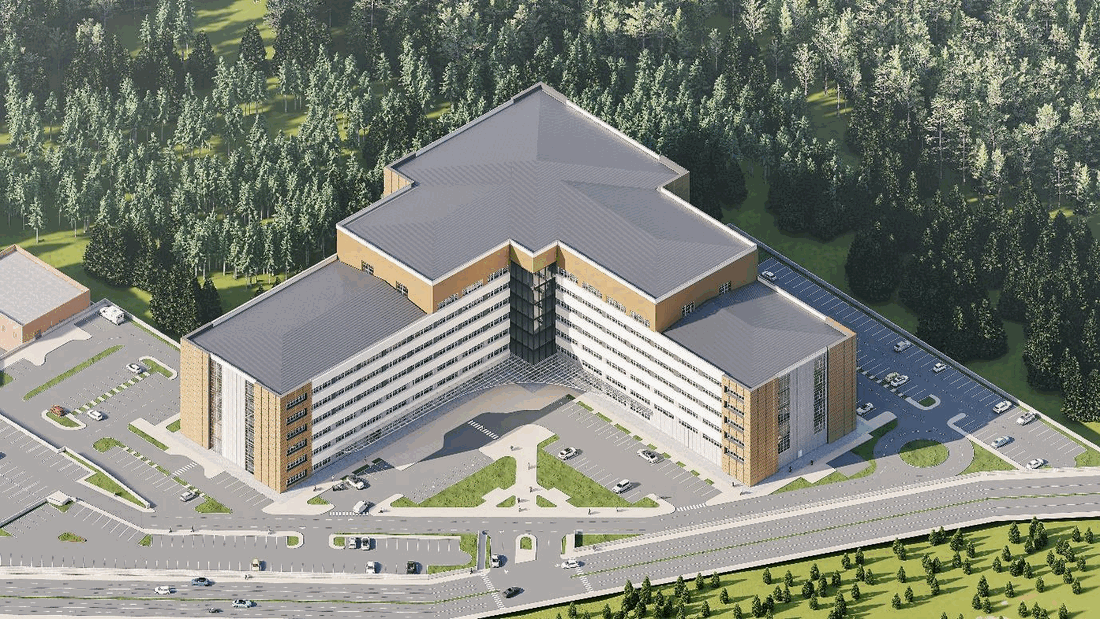

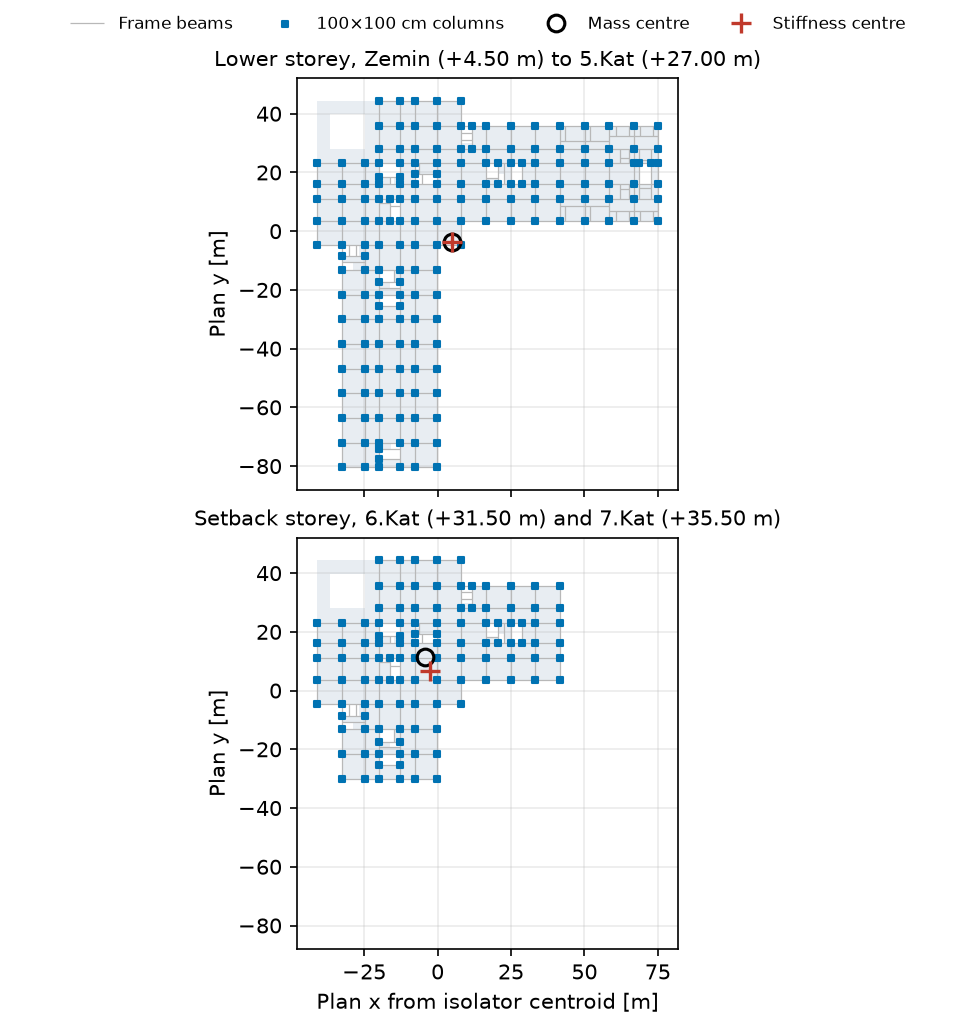

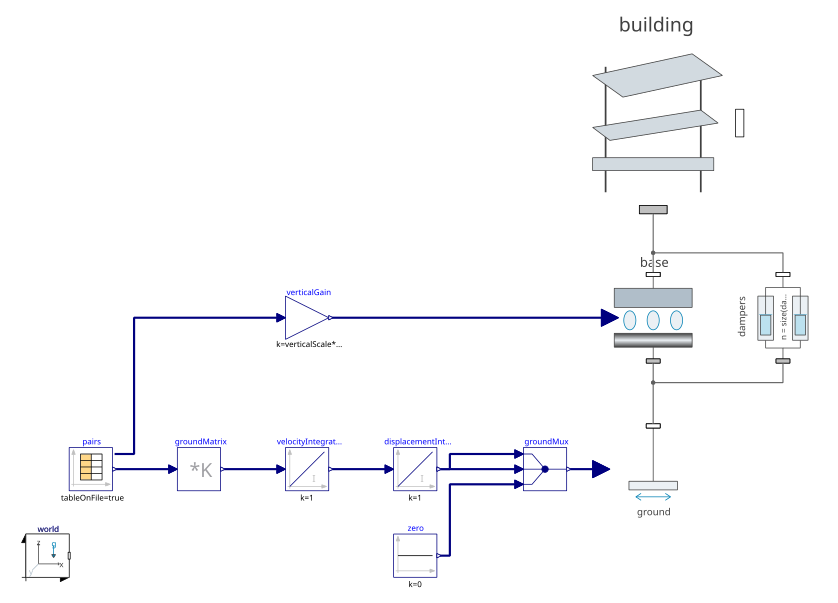

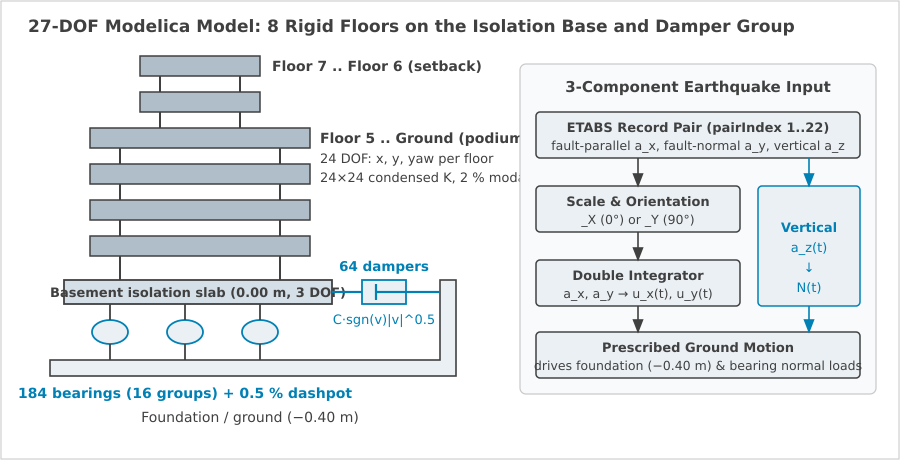

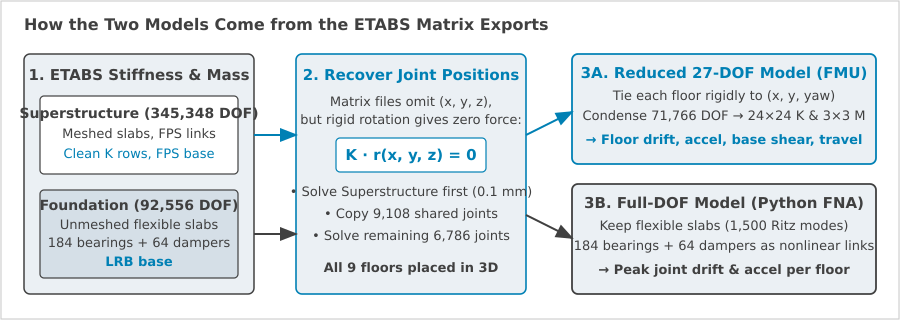

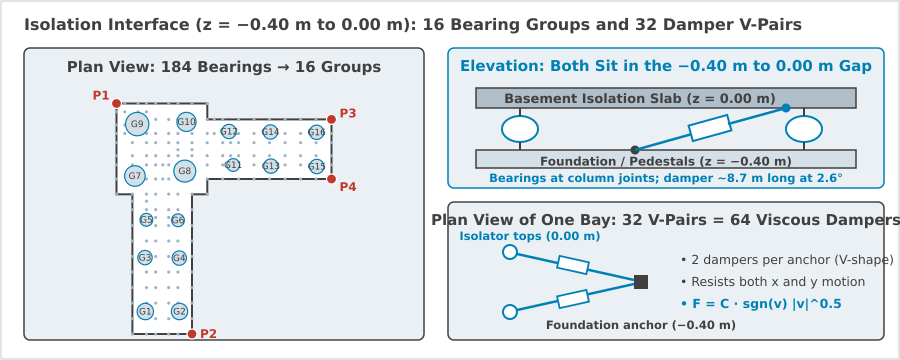

Fixed-base T1..T3, Superstructure (FPS): 0.894, 0.859, 0.719 s
Fixed-base T1..T3, Foundation (LRB): 0.969, 0.942, 0.796 s
=== 8 Floors Condensed from the ETABS Matrices (data/storeys.csv) ===


,storey,height_m,mass_t,kx_MN_m,ky_MN_m,kt_GNm_rad,xm_m,ym_m,ex_m,ey_m
0,Ground (+4.50),4.5,13036.5,18722.7,18878.1,45327.9,4.91,-3.77,-0.15,0.22
1,Floor 1 (+9.00),4.5,12377.2,12825.3,12907.8,31326.2,3.12,-3.88,2.45,-0.76
2,Floor 2 (+13.50),4.5,12254.8,11808.8,11798.3,28329.5,3.00,-3.66,1.65,-1.26
3,Floor 3 (+18.00),4.5,12256.0,11453.7,11442.2,27125.9,2.99,-3.66,1.20,-1.01
4,Floor 4 (+22.50),4.5,12286.5,11219.0,11235.1,25812.5,2.95,-3.64,0.47,-0.23
5,Floor 5 (+27.00),4.5,11908.2,10572.1,10634.2,22674.4,3.32,-3.58,-1.24,1.30
6,Floor 6 (+31.50),4.5,7129.7,7184.3,7163.0,7907.1,-4.45,11.32,1.97,-4.61
7,Floor 7 (+35.50),4.0,6853.7,6545.3,6385.2,6809.2,-4.35,11.16,0.21,-2.17


Isolator reduction check: 184 bearings -> 16 groups (states: 368 -> 32)
  Total weight:          184 bearings = 1,092,325.1 kN | 16 groups = 1,092,325.1 kN
  Tributary centroid:    184 bearings = (1.48, -0.86) m | 16 groups = (1.48, -0.86) m -> balanced to yaw centre (1.484, -0.864) m
  Geometric rgyr:        184 bearings = 46.79 m | 16 groups = 46.12 m (-1.4%)
  Load-weighted rgyr:    184 bearings = 45.25 m | 16 groups = 45.25 m (+0.0%)
  Viscous dampers:       64 units (32 along x, 32 along y), C_nom = 2.35 MN*(s/m)^0.5



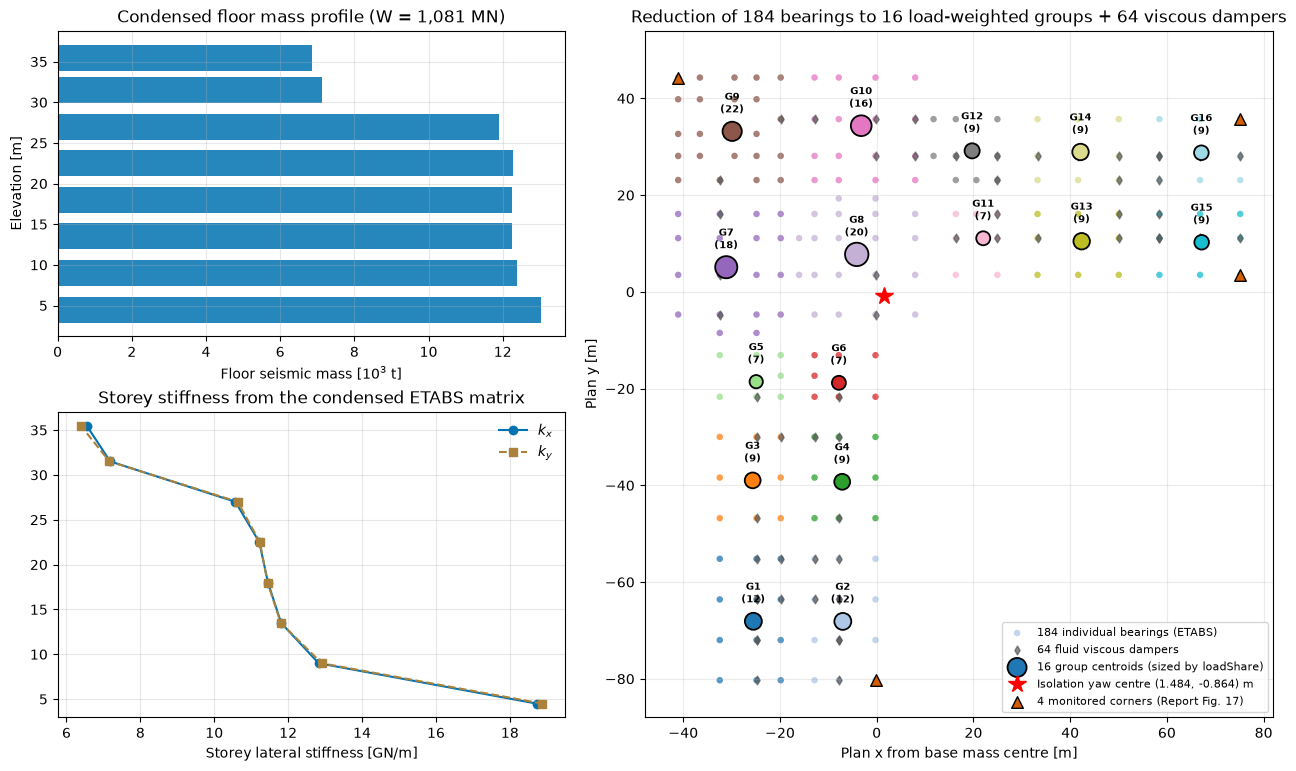

In [2]:
from IPython.display import SVG

for img_name in ("Massing.png", "Plans.png", "ModelDiagram.svg", "StoreyChain.svg", "MatrixPipeline.svg", "IsolationLayer.svg"):
    path = IMAGES / img_name
    if path.exists():
        display(SVG(filename=str(path)) if path.suffix == ".svg" else Image(filename=str(path), width=600))

storeys = pd.read_csv(DATA / "storeys.csv")

from scipy.linalg import eigh
for label, ext in (("Superstructure (FPS)", th.fps_extents()), ("Foundation (LRB)", th.storey_extents())):
    mm, kk = th.matrices(ext)
    periods = 2 * np.pi / np.sqrt(eigh(kk, mm, eigvals_only=True)[:3])
    print(f"Fixed-base T1..T3, {label}: " + ", ".join(f"{t:.3f}" for t in periods) + " s")
isolators = pd.read_csv(DATA / "isolators.csv")
iso_groups = pd.read_csv(DATA / "isolator_groups.csv")
dampers = pd.read_csv(DATA / "dampers.csv")
monitored = pd.read_csv(DATA / "monitored_points.csv")

print("=== 8 Floors Condensed from the ETABS Matrices (data/storeys.csv) ===")
display(
    storeys[
        [
            "storey",
            "height_m",
            "mass_t",
            "kx_MN_m",
            "ky_MN_m",
            "kt_GNm_rad",
            "xm_m",
            "ym_m",
            "ex_m",
            "ey_m",
        ]
    ]
)

# Verify 184 -> 16 isolator reduction equivalence
c_184 = np.average(isolators[["x", "y"]].values, axis=0, weights=isolators["load_kN"])
c_16 = np.average(iso_groups[["x", "y"]].values, axis=0, weights=iso_groups["load_kN"])
g_184 = isolators[["x", "y"]].values.mean(axis=0)
g_16 = np.average(iso_groups[["x", "y"]].values, axis=0, weights=iso_groups["count"])
rgyr_geom_184 = np.sqrt(((isolators[["x", "y"]].values - g_184) ** 2).sum(1).mean())
rgyr_geom_16 = np.sqrt(
    np.average(((iso_groups[["x", "y"]].values - g_16) ** 2).sum(1), weights=iso_groups["count"])
)
rgyr_184 = np.sqrt(
    np.average(((isolators[["x", "y"]].values - c_184) ** 2).sum(1), weights=isolators["load_kN"])
)
rgyr_16 = np.sqrt(
    np.average(((iso_groups[["x", "y"]].values - c_16) ** 2).sum(1), weights=iso_groups["load_kN"])
)
print(
    f"Isolator reduction check: {len(isolators)} bearings -> {len(iso_groups)} groups "
    f"(states: {2 * len(isolators)} -> {2 * len(iso_groups)})"
)
print(
    f"  Total weight:          184 bearings = {isolators['load_kN'].sum():,.1f} kN | "
    f"16 groups = {iso_groups['load_kN'].sum():,.1f} kN"
)
print(
    f"  Tributary centroid:    184 bearings = ({c_184[0]:.2f}, {c_184[1]:.2f}) m | "
    f"16 groups = ({c_16[0]:.2f}, {c_16[1]:.2f}) m -> balanced to yaw centre {th.ISOLATION_CENTRE} m"
)
print(
    f"  Geometric rgyr:        184 bearings = {rgyr_geom_184:.2f} m | "
    f"16 groups = {rgyr_geom_16:.2f} m ({100 * (rgyr_geom_16 / rgyr_geom_184 - 1):+.1f}%)"
)
print(
    f"  Load-weighted rgyr:    184 bearings = {rgyr_184:.2f} m | "
    f"16 groups = {rgyr_16:.2f} m ({100 * round(rgyr_16 / rgyr_184 - 1, 4):+.1f}%)"
)
print(f"  Viscous dampers:       {len(dampers)} units (32 along x, 32 along y), C_nom = 2.35 MN*(s/m)^0.5\n")


elevations = np.cumsum(storeys["height_m"].values)
fig = plt.figure(figsize=(13, 7.6), layout="constrained")
gs = fig.add_gridspec(2, 2, width_ratios=[1.0, 1.35])
ax0 = fig.add_subplot(gs[0, 0])
ax1 = fig.add_subplot(gs[1, 0])
ax2 = fig.add_subplot(gs[:, 1])

ax0.barh(elevations, storeys["mass_t"] / 1e3, height=3.2, color="#0072B2", alpha=0.85)
ax0.set_xlabel("Floor seismic mass [10$^3$ t]")
ax0.set_ylabel("Elevation [m]")
ax0.set_title(f"Condensed floor mass profile (W = {th.WEIGHT / 1e6:,.0f} MN)")
ax0.grid(True, alpha=0.3)

ax1.plot(storeys["kx_MN_m"] / 1e3, elevations, "o-", color="#0072B2", label="$k_x$")
ax1.plot(storeys["ky_MN_m"] / 1e3, elevations, "s--", color="#aa823c", label="$k_y$")
ax1.set_xlabel("Storey lateral stiffness [GN/m]")
ax1.set_title("Storey stiffness from the condensed ETABS matrix")
ax1.legend(frameon=False)
ax1.grid(True, alpha=0.3)

cmap = plt.get_cmap("tab20", 16)
ax2.scatter(
    isolators["x"],
    isolators["y"],
    c=isolators["group"] - 1,
    cmap=cmap,
    s=22,
    alpha=0.75,
    edgecolors="none",
    label="184 individual bearings (ETABS)",
)
ax2.scatter(
    dampers["x"],
    dampers["y"],
    marker="d",
    s=20,
    color="0.35",
    alpha=0.7,
    label="64 fluid viscous dampers",
)
ax2.scatter(
    iso_groups["x"],
    iso_groups["y"],
    c=np.arange(16),
    cmap=cmap,
    s=iso_groups["load_kN"] / 450,
    edgecolors="black",
    linewidths=1.3,
    zorder=4,
    label="16 group centroids (sized by loadShare)",
)
for _, row in iso_groups.iterrows():
    ax2.annotate(
        f"G{int(row['group'])}\n({int(row['count'])})",
        (row["x"], row["y"] + 3.2),
        ha="center",
        va="bottom",
        fontsize=7.5,
        fontweight="bold",
    )
ax2.plot(
    th.ISOLATION_CENTRE[0],
    th.ISOLATION_CENTRE[1],
    "r*",
    markersize=13,
    zorder=5,
    label=f"Isolation yaw centre {th.ISOLATION_CENTRE} m",
)
ax2.scatter(
    monitored["x"],
    monitored["y"],
    marker="^",
    s=70,
    color="#D55E00",
    edgecolors="black",
    zorder=6,
    label="4 monitored corners (Report Fig. 17)",
)
ax2.set_xlabel("Plan x from base mass centre [m]")
ax2.set_ylabel("Plan y [m]")
ax2.set_title("Reduction of 184 bearings to 16 load-weighted groups + 64 viscous dampers")
ax2.set_aspect("equal")
ax2.set_xlim(-48, 82)
ax2.set_ylim(-88, 54)
ax2.legend(loc="lower right", frameon=True, ncol=1, fontsize=8.0)
ax2.grid(True, alpha=0.25)
plt.show()

## 2. Eleven DD-2 & Eleven DD-1 Earthquake Suites & Response Spectra

Unlike single-suite studies, the Bolu hospital design report defines two distinct 11-pair ground-motion suites in ETABS ([`data/load_cases.csv`](data/load_cases.csv)): a 475-year **DD-2 (`DBE`)** suite (`RSN 173, 181, 1158, 1605, 1762, 5825, 5829, 5831, 6927, 6960, 6962`, applied horizontally without vertical excitation) and a 2,475-year **DD-1 (`MCE`)** suite (`RSN 173, 181, 1158, 1176, 1762, 5825, 5829, 5831, 6893, 6927, 6952`, applied with three components including vertical excitation).

Choose any `pair_id` (`1` to `11`) and hazard `level` (`"DD-2"` or `"DD-1"`) below to inspect its scaled fault-parallel (`FP`), fault-normal (`FN`), and vertical (`UP`) acceleration histories and compare its 5 %-damped `SRSS` and `RotD100` response spectra against the Bolu site target spectra ([`data/spectrum.csv`](data/spectrum.csv)).

,case,level,rsn,orientation,dof,function,factor,duration,output_step
0,MCE_173-V,DD-1,173,V,U1,RSN173_FP,2.898000,37.075,0.005
1,MCE_173-V,DD-1,173,V,U2,RSN173_FN,2.898063,37.075,0.005
2,MCE_173-V,DD-1,173,V,U3,173mce_V,1.000000,37.075,0.005
13,MCE_181-V,DD-1,181,V,U1,RSN181_FP,1.172000,39.100,0.005
14,MCE_181-V,DD-1,181,V,U2,RSN181_FN,1.172273,39.100,0.005
15,MCE_181-V,DD-1,181,V,U3,181mce_V,1.000000,39.100,0.005
26,MCE_1158-V,DD-1,1158,V,U1,RSN1158_FP,2.711000,27.200,0.005
27,MCE_1158-V,DD-1,1158,V,U2,RSN1158_FN,2.710499,27.200,0.005
28,MCE_1158-V,DD-1,1158,V,U3,1158mce_V,1.000000,27.200,0.005
39,MCE_1176-V,DD-1,1176,V,U1,RSN1176_FP,1.713000,35.000,0.005


Selected DD-1 Pair 3 (RSN 1158) | Duration: 27.20 s | Horizontal scale factor: 2.711
  Scaled PGA : FP (x) = 0.987 g, FN (y) = 0.845 g, UP (z) = 1.083 g


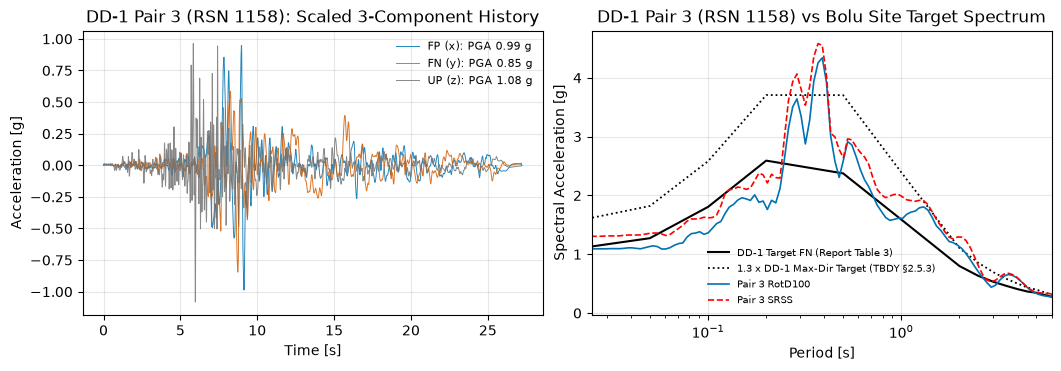

In [3]:
# --- Interactive Record Pair & Response Spectrum Inspector ---
pair_id = 3          # 1..11 (e.g. 3 = RSN 1158 Kocaeli, 4 = RSN 1176 Kocaeli, 1 = RSN 173 Imperial Valley)
level = "DD-1"       # "DD-2" (475-yr DBE) or "DD-1" (2475-yr MCE)

if not (1 <= pair_id <= 11):
    raise ValueError(f"pair_id must be between 1 and 11, got {pair_id}")
if level not in ("DD-2", "DD-1"):
    raise ValueError(f"level must be 'DD-2' or 'DD-1', got {level!r}")

lc_df = pd.read_csv(DATA / "load_cases.csv")
spec_df = pd.read_csv(DATA / "spectrum.csv")

suite_summary = (
    lc_df[lc_df["orientation"] == "X"]
    .pivot_table(index=["level", "rsn", "case", "duration"], columns="dof", values=["function", "factor"], aggfunc="first")
)
display(lc_df[(lc_df["level"] == level) & (lc_df["orientation"].isin(["X", "V"]))].drop_duplicates(subset=["rsn", "dof"]))

rsn = rp.RECORDS[level][pair_id - 1]
rows_rsn = [r for r in rp.load_cases() if r["level"] == level and r["rsn"] == rsn]
dur = max(r["duration"] for r in rows_rsn)
n_pts = round(dur / rp.DT) + 1
ax_x, ax_y, ax_z = (a / rp.GRAVITY for a in rp.triplet(level, rsn, n_pts))
time_axis = np.arange(n_pts) * rp.DT
sf = rows_rsn[0]["factor"]

print(f"Selected {level} Pair {pair_id} (RSN {rsn}) | Duration: {dur:.2f} s | Horizontal scale factor: {sf:.3f}")
print(
    f"  Scaled PGA : FP (x) = {np.abs(ax_x).max():.3f} g, "
    f"FN (y) = {np.abs(ax_y).max():.3f} g, "
    f"UP (z) = {np.abs(ax_z).max():.3f} g"
)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), layout="constrained")
for comp, sig, col in (("FP (x)", ax_x, "#0072B2"), ("FN (y)", ax_y, "#D55E00"), ("UP (z)", ax_z, "0.45")):
    if np.abs(sig).max() > 0:
        axes[0].plot(time_axis, sig, lw=0.7, alpha=0.85, color=col, label=f"{comp}: PGA {np.abs(sig).max():.2f} g")
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Acceleration [g]")
axes[0].set_title(f"{level} Pair {pair_id} (RSN {rsn}): Scaled 3-Component History")
axes[0].legend(fontsize=8, frameon=False)
axes[0].grid(True, alpha=0.3)

periods = rp.CHECK_PERIODS
w2 = (2 * np.pi / periods) ** 2
sa_x = w2 * np.abs(rp.response_history(ax_x * rp.GRAVITY, periods)).max(axis=0) / rp.GRAVITY
sa_y = w2 * np.abs(rp.response_history(ax_y * rp.GRAVITY, periods)).max(axis=0) / rp.GRAVITY
sa_srss = np.hypot(sa_x, sa_y)
sa_rot = rp.rotd100(ax_x * rp.GRAVITY, ax_y * rp.GRAVITY, periods) / rp.GRAVITY

col_fn = "dd1_fn_g" if level == "DD-1" else "dd2_fn_g"
col_rot = "dd1_max_rot_g" if level == "DD-1" else "dd2_max_rot_g"
axes[1].plot(spec_df["period_s"], spec_df[col_fn], "k-", lw=1.5, label=f"{level} Target FN (Report Table {'3' if level == 'DD-1' else '5'})")
axes[1].plot(spec_df["period_s"], 1.3 * spec_df[col_rot], "k:", lw=1.3, label=f"1.3 x {level} Max-Dir Target (TBDY §2.5.3)")
axes[1].plot(periods, sa_rot, color="#0072B2", lw=1.2, label=f"Pair {pair_id} RotD100")
axes[1].plot(periods, sa_srss, "r--", lw=1.2, label=f"Pair {pair_id} SRSS")
axes[1].set_xscale("log")
axes[1].set_xlim(0.025, 6.0)
axes[1].set_xlabel("Period [s]")
axes[1].set_ylabel("Spectral Acceleration [g]")
axes[1].set_title(f"{level} Pair {pair_id} (RSN {rsn}) vs Bolu Site Target Spectrum")
axes[1].legend(fontsize=7.5, frameon=False)
axes[1].grid(True, alpha=0.3)
plt.show()

## 3. Verification Against the ETABS Design Report & Isolator Plan Displacements

Set `run_live_fmu = True` to re-simulate all 132 verification runs (`nominal`, `upper`, `lower` for `BoluFrictionPendulum.fmu`; `lrb_upper`, `lrb_lower` for `BoluLeadRubber.fmu`; `fixed` for `BoluFixedBase.fmu`) via `FMPy` with your chosen isolator and damper parameters, or leave `run_live_fmu = False` to plot immediately from the pre-computed verification cache in `data/report_match.json`.

Drift and floor acceleration are read at the extreme joints of each storey with the floor twist included. LRB is checked against Report Tables 18 and 20, and FPS drift against the ETABS `Superstructure` run (`data/etabs_fps_drifts.json`). The report's FPS drift and acceleration (Tables 17 and 19) are not plotted. Figure 4 (`TravelHistory.gif`) animates the largest DD-1 lower-bound run inside the `1.04 m` capacity, Modelica 27-DOF against the full 3D model of the ETABS matrices (bearing P-Delta off) (`data/full_model_travel_dd1low_p4_r1.npz`). It is redrawn only in live mode or when missing. The cell also shows the 4-point DD-1 orbits (`ReportTravel.png`), the solver check (`ModelicaVsPython27DOF.png`), the 16-group plan orbits for both bearing types, and the plots in `verification/` that add the full model and the LRB parity.

ETABS Superstructure vs Design Report Table 19 (FPS drift [%], X, Y):
 Ground   Rep  0.31  0.30 | ETABS DD-2  0.22  0.21 (0.70,0.70) | DD-1  0.29  0.28 (0.92,0.92)
 Floor 1  Rep  0.42  0.36 | ETABS DD-2  0.28  0.33 (0.66,0.91) | DD-1  0.37  0.44 (0.88,1.21)
 Floor 2  Rep  0.42  0.38 | ETABS DD-2  0.27  0.27 (0.64,0.71) | DD-1  0.37  0.36 (0.88,0.94)
 Floor 3  Rep  0.41  0.40 | ETABS DD-2  0.26  0.25 (0.63,0.64) | DD-1  0.36  0.33 (0.88,0.83)
 Floor 4  Rep  0.38  0.40 | ETABS DD-2  0.23  0.23 (0.60,0.57) | DD-1  0.32  0.29 (0.85,0.73)
 Floor 5  Rep  0.32  0.37 | ETABS DD-2  0.20  0.20 (0.63,0.55) | DD-1  0.29  0.26 (0.92,0.70)
 Floor 6  Rep  0.38  0.45 | ETABS DD-2  0.23  0.25 (0.60,0.55) | DD-1  0.34  0.32 (0.88,0.72)
 Floor 7  Rep  0.26  0.30 | ETABS DD-2  0.14  0.15 (0.55,0.51) | DD-1  0.22  0.20 (0.83,0.67)
FPS drift [%] X, Y: ETABS Superstructure | full-model joint maximum | full-model floor mean | 24-DOF mass centre | 24-DOF corners
 Ground    0.22  0.21 |  0.22  0.21 |  0.19  0.1

Wrote C:\Users\senol\Documents\GitHub\StructuralMembers\blogs\hospital_design_bolu\public\images\ReportDrift.png
Wrote C:\Users\senol\Documents\GitHub\StructuralMembers\blogs\hospital_design_bolu\public\images\ReportDriftLRB.png
Wrote C:\Users\senol\Documents\GitHub\StructuralMembers\blogs\hospital_design_bolu\public\images\ReportAccelerationLRB.png
Wrote C:\Users\senol\Documents\GitHub\StructuralMembers\blogs\hospital_design_bolu\public\verification\ReportDrift.png
Wrote C:\Users\senol\Documents\GitHub\StructuralMembers\blogs\hospital_design_bolu\public\verification\ReportAcceleration.png
Wrote C:\Users\senol\Documents\GitHub\StructuralMembers\blogs\hospital_design_bolu\public\verification\ReportDriftLRB.png
Wrote C:\Users\senol\Documents\GitHub\StructuralMembers\blogs\hospital_design_bolu\public\verification\ReportAccelerationLRB.png
Wrote C:\Users\senol\Documents\GitHub\StructuralMembers\blogs\hospital_design_bolu\public\verification\ReportDriftMCE.png
Wrote C:\Users\senol\Documents

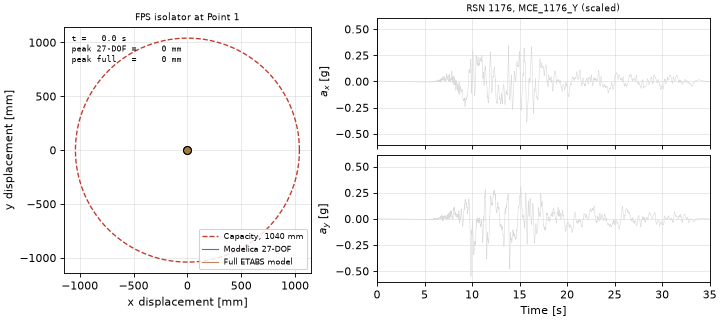

images/ReportAccelerationLRB.png


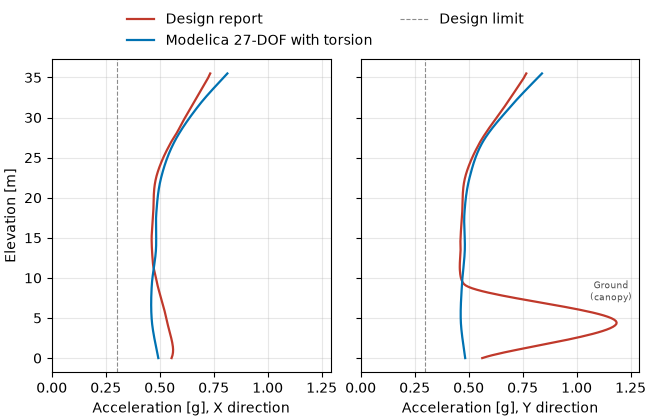

images/ReportDriftLRB.png


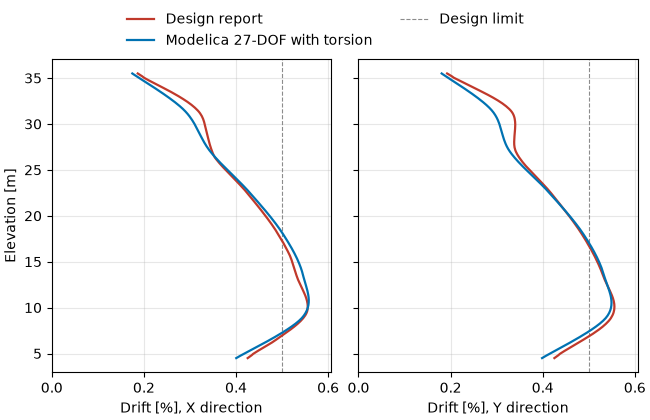

images/ReportDrift.png


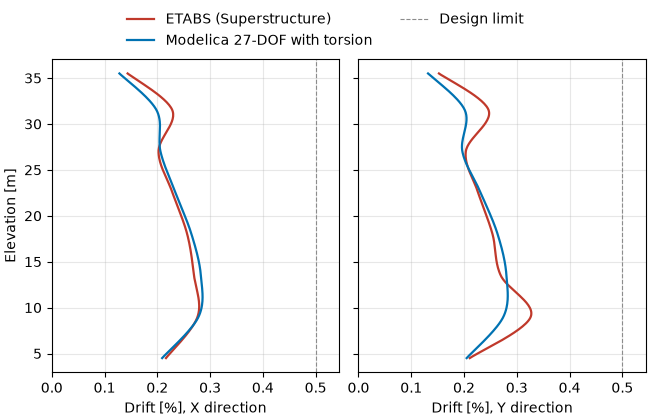

images/ReportTravel.png


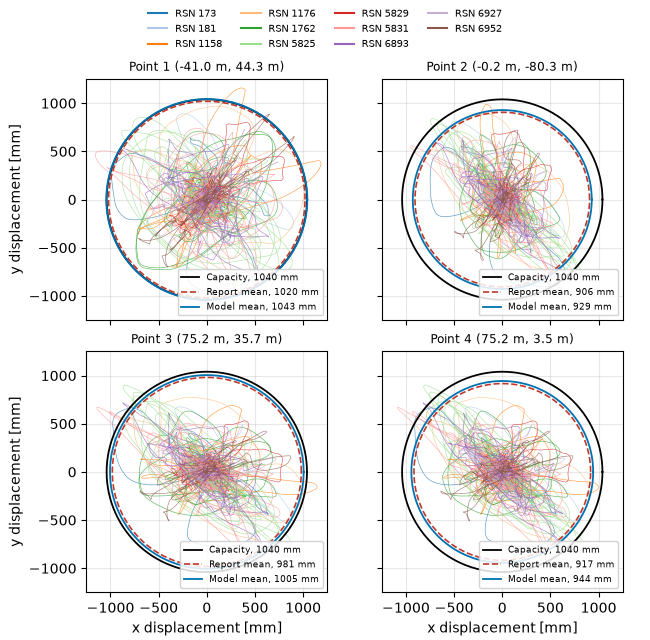

images/ModelicaVsPython27DOF.png


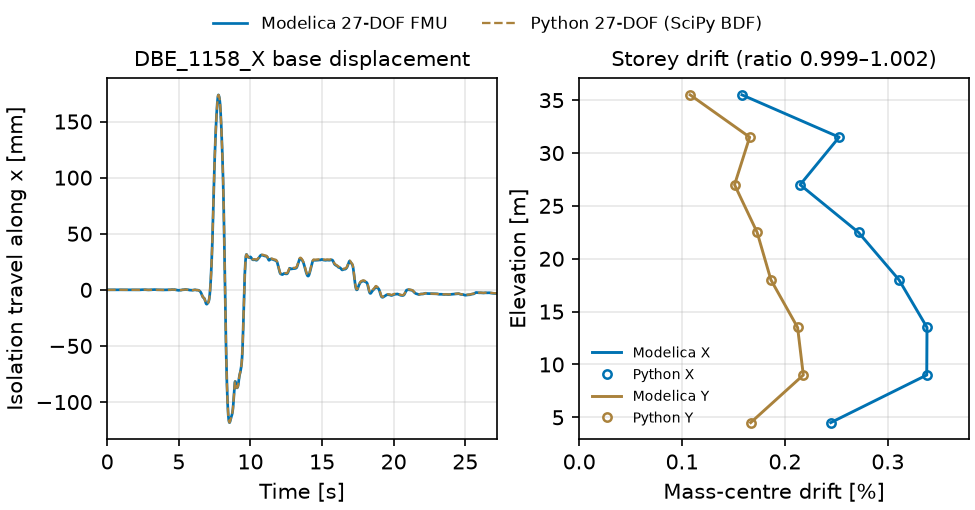

images/IsolatorPlanFrictionPendulum.png


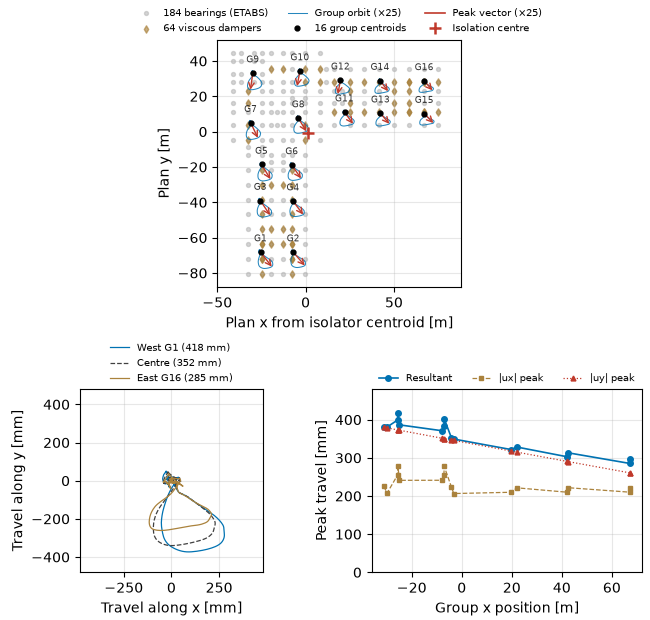

images/IsolatorPlanLeadRubber.png


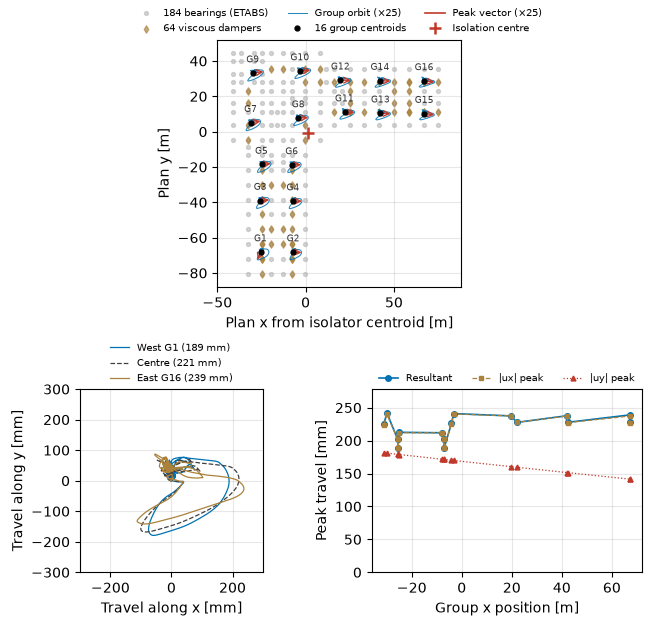

verification/ReportDrift.png


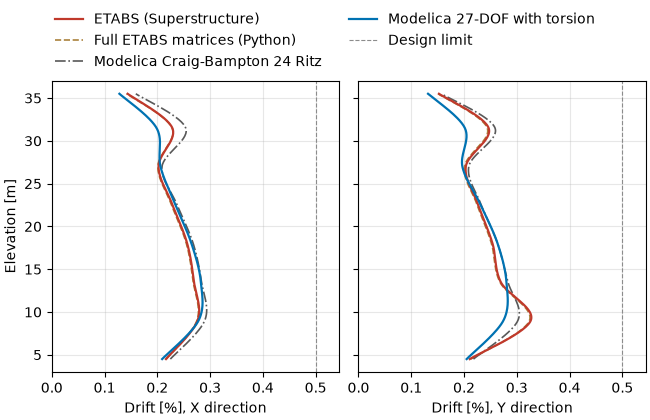

verification/ReportAcceleration.png


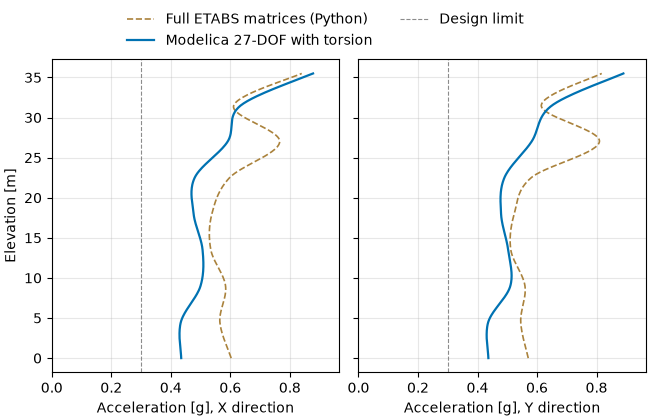

verification/ReportDriftLRB.png


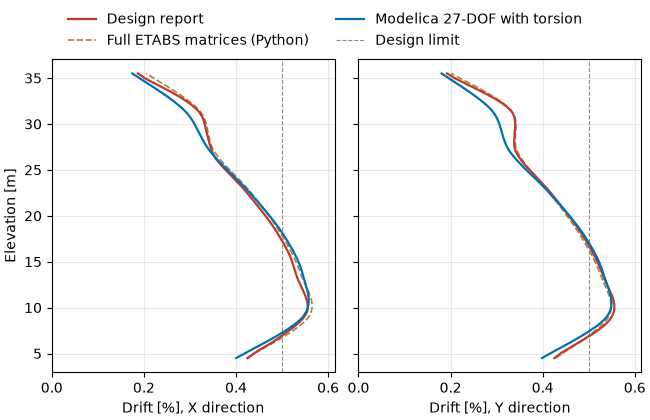

verification/ReportAccelerationLRB.png


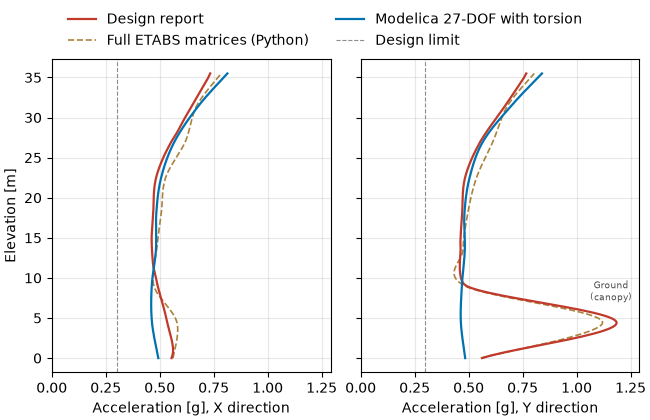

verification/ReportMatchLRB.png


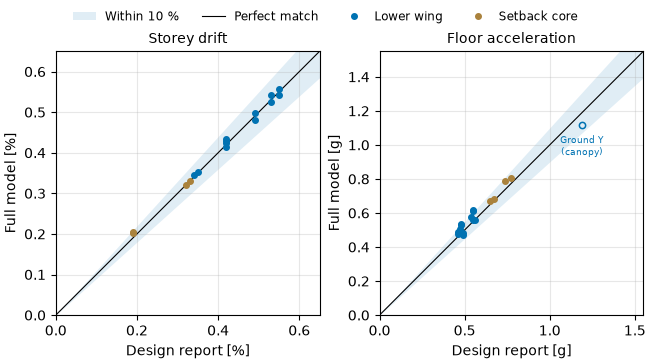

verification/ReportDriftLevels.png


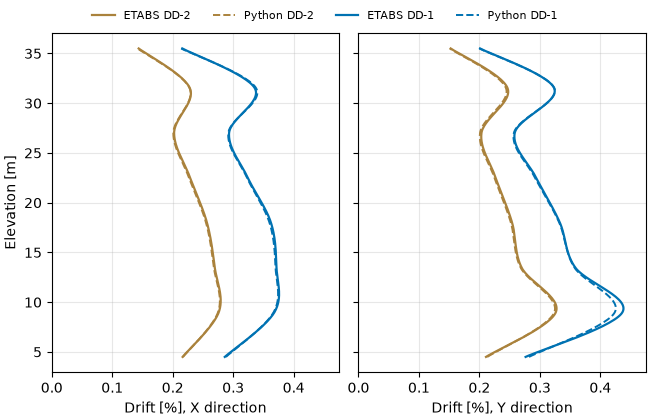

In [4]:
# --- Interactive FPS & Viscous Damper Report Parameters ---
th.PENDULUM_RADIUS = 7.4          # Effective pendulum radius R [m]
th.FRICTION_NOMINAL = 0.055       # Nominal fast friction coefficient mu [-]
th.DAMPER_NOMINAL = 2.35e6        # Nominal viscous damper coefficient C [N*(s/m)^0.5]
th.DAMPING = 0.02                 # Retained superstructure modal damping ratio [-]
th.RETAINED_MODES = 24            # Retained fixed-base modes [-]
th.TRUNCATED_DAMPING = 0.02       # Truncated higher-mode damping ratio [-]
th.ISOLATION_DAMPING = 0.005      # Isolation mode linear damping ratio [-]
th.SLIP = 0.001                   # Slider yield displacement [m]
run_live_fmu = False              # Set True to re-simulate on the FMUs via FMPy
workers = 8                       # Parallel FMPy worker processes

th.main_pairs(workers=workers, live=run_live_fmu)
for folder, img_name in (
    (IMAGES, "TravelHistory.gif"),
    (IMAGES, "ReportAccelerationLRB.png"),
    (IMAGES, "ReportDriftLRB.png"),
    (IMAGES, "ReportDrift.png"),
    (IMAGES, "ReportTravel.png"),
    (IMAGES, "ModelicaVsPython27DOF.png"),
    (IMAGES, "IsolatorPlanFrictionPendulum.png"),
    (IMAGES, "IsolatorPlanLeadRubber.png"),
    (th.VERIFICATION, "ReportDrift.png"),
    (th.VERIFICATION, "ReportAcceleration.png"),
    (th.VERIFICATION, "ReportDriftLRB.png"),
    (th.VERIFICATION, "ReportAccelerationLRB.png"),
    (th.VERIFICATION, "ReportMatchLRB.png"),
    (th.VERIFICATION, "ReportDriftLevels.png"),
):
    if (folder / img_name).exists():
        print(f"{folder.name}/{img_name}")
        display(Image(filename=str(folder / img_name), width=600))

## 4. Interactive Bearing Parameter Sweep on FMUs (Figure 8)

The grid uses manufacturer catalogue data (Maurer, CPA, Bridgestone, and the Turkish makers Arsan, Fago, TİS and Arfen; see `technical_notes.md` §4). Modify the FPS radii and friction coefficients, the LRB outer diameter, lead ratio, rubber thickness and shear modulus, and the code limits (`DRIFT_LIMIT`, `ACCELERATION_LIMIT`, `DISPLACEMENT_CAPACITY`, `SHEAR_LIMIT`, `STRAIN_LIMIT`) below. The 64 nonlinear fluid viscous dampers stay fixed at the report design, with $C$ = `2.35` (nominal), `2.825` (upper) and `2.00` (lower) MN·(s/m)^0.5. Bearings and dampers always take the same bound, and mixed bounds are not run. Set `run_live_sweep = True` to evaluate new candidate designs on `fmu/BoluFrictionPendulum.fmu` and `fmu/BoluLeadRubber.fmu` with `FMPy` (the full grid took `3 h 34 min` on eight workers), or leave `run_live_sweep = False` to inspect the 107 pre-computed designs in `data/bearing_sweep.json`. Base shear and drift use the upper bound, floor acceleration the nominal values and $D_{TM}$ the lower bound (TBDY 2018 §14.3.6 and §14.3.10).

,design,period_s,drift_%,acc_g,shear_W,travel_m,restoring_W,strain_%,shear_ok,drift_ok,travel_ok,strain_ok,acc_ok,meets_design,highlight
0,"FPS R 2 m, mu 0.02",2.84,0.241,0.477,0.1624,0.921,0.230,NaN,True,True,True,True,False,True,Lowest-acceleration feasible FPS
1,"FPS R 2 m, mu 0.03",2.84,0.249,0.549,0.1595,0.864,0.216,NaN,True,True,True,True,False,True,
2,"FPS R 2 m, mu 0.055",2.84,0.289,0.701,0.1726,0.736,0.184,NaN,True,True,True,True,False,True,
3,"FPS R 2 m, mu 0.08",2.84,0.347,0.826,0.1958,0.623,0.156,NaN,True,True,True,True,False,True,
4,"FPS R 2 m, mu 0.1",2.84,0.399,0.919,0.2180,0.549,0.137,NaN,False,True,True,True,False,False,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102,LRB D1500 L375 Tr250 G0.6,2.44,0.639,0.752,0.3288,0.505,0.171,202.0,False,False,True,True,False,False,
103,LRB D1500 L375 Tr300 G0.4,3.27,0.587,0.678,0.3101,0.613,0.115,204.0,False,False,True,True,False,False,
104,LRB D1500 L375 Tr300 G0.6,2.67,0.619,0.721,0.3220,0.539,0.152,180.0,False,False,True,True,False,False,
105,LRB D1500 L375 Tr450 G0.4,4.01,0.558,0.547,0.2989,0.693,0.087,154.0,False,False,True,True,False,False,


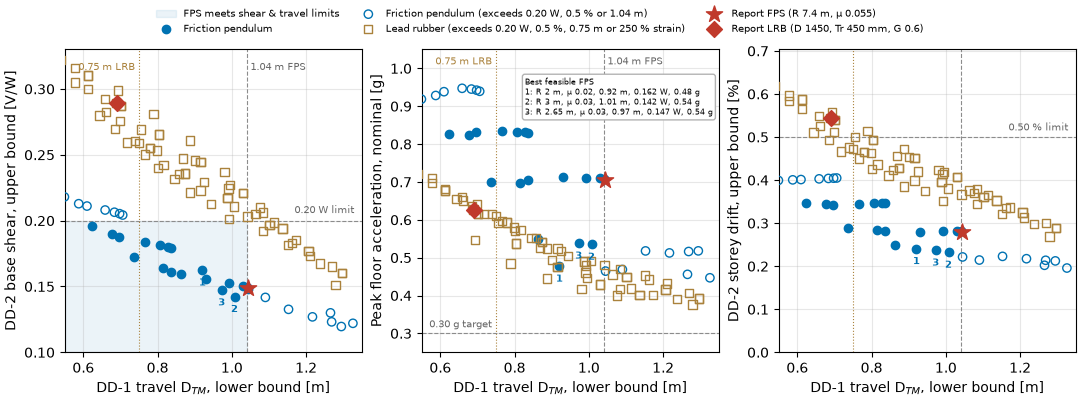

In [5]:
# --- Interactive Bearing Sweep Parameters & Code Limits ---
fps_radii = bs.FPS_GRID["radius"]            # Candidate FPS radii R [m]
fps_frictions = bs.FPS_GRID["friction"]      # Candidate FPS nominal friction coefficients [-]
lrb_diameters = bs.LRB_GRID["diameter"]      # Candidate LRB outer diameters Do [m]
lrb_lead_ratios = bs.LRB_GRID["lead_ratio"]  # Candidate lead core diameter ratios dl/Do [-]
lrb_thicknesses = bs.LRB_GRID["thickness"]   # Candidate total rubber thicknesses Tr [m]
lrb_moduli = bs.LRB_GRID["modulus"]          # Candidate rubber shear moduli G [Pa]

th.DRIFT_LIMIT = 0.005                   # Occupied storey drift limit (0.5 %)
th.ACCELERATION_LIMIT = 0.30             # Medical equipment floor acceleration target [g]
th.DISPLACEMENT_CAPACITY = 1.04          # Bearing travel capacity [m]
bs.SHEAR_LIMIT = 0.20                    # Ministry DD-2 upper-bound base shear limit [V/W]
bs.STRAIN_LIMIT = 2.5                    # LRB rubber shear strain limit [-]
run_live_sweep = False                   # Set True to run the grid above via FMPy

if run_live_sweep and bs.simulate_fmu is None:
    print(
        "Note: fmpy is not installed (run: pip install fmpy); "
        "loading pre-computed 107-design sweep from data/bearing_sweep.json."
    )
    run_live_sweep = False

if run_live_sweep:
    from itertools import product
    designs = (
        [bs.fps_design(r, mu) for r, mu in product(fps_radii, fps_frictions)]
        + [bs.lrb_design(**bs.REPORT_LRB)]
        + [bs.lrb_design(**bs.catalogue_lrb(*p)) for p in product(
            lrb_diameters, lrb_lead_ratios, lrb_thicknesses, lrb_moduli)]
    )
    designs = [d for d in designs if d["period"] <= bs.MAX_PERIOD and d["wind_ok"]]
    sweep_rows = [bs.evaluate(d, workers=8) for d in designs]
else:
    sweep_rows = []
    for folder in (th.DATA, th.RUNS):
        for path in sorted(folder.glob("bearing_sweep*.json")):
            sweep_rows.extend(json.loads(path.read_text(encoding="utf-8")))

_HIGHLIGHTS = {
    "FPS R 7.4 m, mu 0.055": "Report FPS (selected)",
    bs.REPORT_LRB["label"]: "Report LRB (Table 11)",
    "FPS R 2 m, mu 0.02": "Lowest-acceleration feasible FPS",
    "FPS R 7.4 m, mu 0.08": "Report radius, higher friction",
    "LRB D1100 L220 Tr300 G0.6": "Closest LRB (shear met)",
    "LRB D1100 L220 Tr250 G0.6": "Closest LRB (travel met)",
}

if sweep_rows:
    df_sweep = pd.DataFrame([r for r in sweep_rows if "drift" in r]).drop_duplicates(
        subset=["design"], keep="last"
    )
    df_sweep["period_s"] = df_sweep["period"].round(2)
    df_sweep["drift_%"] = (100 * df_sweep["drift"]).round(3)
    df_sweep["acc_g"] = df_sweep["acceleration"].round(3)
    df_sweep["shear_W"] = df_sweep["shear"].round(4)
    df_sweep["travel_m"] = df_sweep["travel"].round(3)
    df_sweep["restoring_W"] = df_sweep["restoring"].round(3)
    df_sweep["strain_%"] = (100 * df_sweep["strain"]).round(0)
    df_sweep["strain_ok"] = df_sweep["strain"].fillna(0.0) <= bs.STRAIN_LIMIT
    df_sweep["shear_ok"] = df_sweep["shear"] <= bs.SHEAR_LIMIT
    df_sweep["drift_ok"] = df_sweep["drift"] <= th.DRIFT_LIMIT
    df_sweep["acc_ok"] = df_sweep["acceleration"] <= th.ACCELERATION_LIMIT
    df_sweep["travel_ok"] = df_sweep["travel"] <= th.DISPLACEMENT_CAPACITY
    df_sweep["meets_design"] = (
        (df_sweep["period"] <= bs.MAX_PERIOD)
        & df_sweep["wind_ok"]
        & (df_sweep["restoring"] >= bs.RESTORING)
        & df_sweep["shear_ok"]
        & df_sweep["drift_ok"]
        & df_sweep["travel_ok"]
        & df_sweep["strain_ok"]
    )
    df_sweep["highlight"] = df_sweep["design"].map(_HIGHLIGHTS).fillna("")
    display(
        df_sweep[
            [
                "design",
                "period_s",
                "drift_%",
                "acc_g",
                "shear_W",
                "travel_m",
                "restoring_W",
                "strain_%",
                "shear_ok",
                "drift_ok",
                "travel_ok",
                "strain_ok",
                "acc_ok",
                "meets_design",
                "highlight",
            ]
        ]
    )

bs.plot(sweep_rows)
if (th.IMAGES / "BearingSweep.png").exists():
    display(Image(filename=str(th.IMAGES / "BearingSweep.png"), width=600))